# 20 Newsgroups: EmbeddingGemma 2, UMAP, and IMSTE

Load the cached text vectors, fit UMAP and IMSTE, then compare category layouts. Set `IMSTE_SETTINGS["label_strength"]` to zero for unsupervised fitting or positive to use the category labels.

Run [prepare_20newsgroups_dataset.ipynb](dataset_setup/prepare_20newsgroups_dataset.ipynb) first. Install notebook dependencies with `%pip install -e ".[notebook,preprocessing]"`.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
                 if (path / "pyproject.toml").is_file() and (path / "imste").is_dir())
for local_path in (REPO_ROOT, REPO_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)

import importlib
import newsgroups
newsgroups = importlib.reload(newsgroups)
load_20newsgroups_dataset = newsgroups.load_20newsgroups_dataset
fit_20newsgroups_umap = newsgroups.fit_20newsgroups_umap
fit_20newsgroups_imste = newsgroups.fit_20newsgroups_imste
plot_20newsgroups_layouts = newsgroups.plot_20newsgroups_layouts

DATA_DIR = REPO_ROOT / "data" / "20newsgroups"
CACHE_INDEX = -1  # Use the most recently created cache.
X, texts, labels, indices, category_names, manifest = load_20newsgroups_dataset(DATA_DIR, CACHE_INDEX)

RANDOM_STATE = int(manifest["random_state"])
COLOR_LEVEL = 1  # Choose 1 (broad), 2 (middle), or 3 (specific) newsgroup groups.
RUN_IMSTE_TUNING = True  # Enable the optional balanced-subset search below.
IMSTE_SETTINGS = {
    "n_msts": 64,
    "negative_ratio": 2,
    "n_epochs": 1000,
    "label_strength": 2.0,  # Set positive for label-aware tuning and fitting.
    "gravity_strength": 0.1,
    "mean_shift_iterations": 0,
    "verbose": True,
}


Available embedding caches:
  0: gemma2 · 1,000 rows · created 2026-11-20 22:37:35 · 20newsgroups_50_per_category_seed42_embeddinggemma2_manifest.json
  1: tfidf · 3,000 rows · created 2026-11-20 22:40:16 · 20newsgroups_150_per_category_seed42_tfidf_manifest.json
  2: tfidf · 18,846 rows · created 2026-11-20 22:41:29 · 20newsgroups_full_seed42_tfidf_manifest.json
  3: gemma2 · 18,846 rows · created 2026-11-20 23:25:34 · 20newsgroups_full_seed42_embeddinggemma2_manifest.json
Loaded 18,846 messages · 768 features · gemma2: google/embeddinggemma-2


## Optionally tune IMSTE

Enable `RUN_IMSTE_TUNING` in the settings cell to search on a balanced, reproducible subset. The search is off by default. Install the optional dependency with `%pip install -e ".[tuning]"`.

In [2]:
import time
import pandas as pd
from IPython.display import display
from newsgroups import tune_20newsgroups_imste

TUNE_MAX_PER_CATEGORY = 200
TUNE_EPOCHS = 100
TUNE_TRIALS = 40
TUNE_COVERAGE_WEIGHT = 0.3  # Balance category accuracy against spatial coverage.
TUNE_SEARCH_SPACE = {
    "n_msts": (2, 64),
    "negative_ratio": (1, 10),
    "logistic_margin": (0.25, 2.0),
    "logistic_temperature": (0.1, 1.0),
    "lambda_rep": (0.25, 0.75),
    "gravity_strength": (0.0, 1.0),
    "gravity_resolution": (0.5, 2.0),
    "gravity_min_dist": (0.0, 1.0),
    "mean_shift_iterations": (0, 5),
}

IMSTE_TUNED_PARAMS = {}
tuning_seconds = 0.0
if RUN_IMSTE_TUNING:
    tuning_started = time.perf_counter()
    tune_result, tune_indices = tune_20newsgroups_imste(
        X,
        labels,
        random_state=RANDOM_STATE,
        max_per_category=TUNE_MAX_PER_CATEGORY,
        n_epochs=TUNE_EPOCHS,
        n_trials=TUNE_TRIALS,
        coverage_weight=TUNE_COVERAGE_WEIGHT,
        search_space=TUNE_SEARCH_SPACE,
        base_settings=IMSTE_SETTINGS,
    )
    tuning_seconds = time.perf_counter() - tuning_started
    IMSTE_TUNED_PARAMS = tune_result.best_params
    IMSTE_SETTINGS.update(IMSTE_TUNED_PARAMS)
    print(f"Best tuning accuracy: {tune_result.best_accuracy:.3f}")
    print(f"Best tuning coverage: {tune_result.best_coverage:.3f}")
    print("Selected IMSTE settings:", IMSTE_TUNED_PARAMS)
    tuning_trials = pd.DataFrame(tune_result.x_iters, columns=TUNE_SEARCH_SPACE)
    tuning_trials["accuracy"] = tune_result.cv_scores
    tuning_trials["coverage"] = tune_result.coverage_scores
    tuning_trials["objective"] = tune_result.objective_scores
    display(tuning_trials.sort_values("objective", ascending=False).reset_index(drop=True))
else:
    print("Skipping IMSTE tuning; using the configured settings.")


Tuning on 4,000 messages across 20 categories
Best tuning accuracy: 0.610
Best tuning coverage: 0.412
Selected IMSTE settings: {'n_msts': np.int64(6), 'negative_ratio': np.int64(8), 'logistic_margin': 0.25, 'logistic_temperature': 0.1, 'lambda_rep': 0.75, 'gravity_strength': 0.0, 'gravity_resolution': 2.0, 'gravity_min_dist': 0.545081186961594, 'mean_shift_iterations': np.int64(0)}


,n_msts,negative_ratio,logistic_margin,logistic_temperature,lambda_rep,gravity_strength,gravity_resolution,gravity_min_dist,mean_shift_iterations,accuracy,coverage,objective
0,6,8,0.250000,0.100000,0.750000,0.000000,2.000000,0.545081,0,0.61000,0.411932,0.550580
1,29,10,0.273049,0.113886,0.737318,0.000000,2.000000,0.000000,0,0.62975,0.292640,0.528617
2,14,10,0.331445,0.167081,0.456433,0.000000,2.000000,0.470183,0,0.63350,0.223476,0.510493
3,34,5,0.271000,0.181638,0.615733,0.010646,1.762457,0.386443,0,0.63100,0.228911,0.510373
4,43,10,0.664065,0.234291,0.568016,0.000000,1.879441,0.015259,0,0.63500,0.178676,0.498103
5,2,10,0.250000,0.261079,0.332759,0.000000,2.000000,0.558336,0,0.58250,0.268436,0.488281
6,31,10,0.250000,0.100000,0.750000,0.000000,2.000000,0.853219,5,0.62000,0.163694,0.483108
7,64,10,0.250000,0.100000,0.731894,0.000000,2.000000,0.000000,2,0.62900,0.141043,0.482613
8,26,4,0.250000,0.100000,0.250000,0.000000,2.000000,0.000000,1,0.62350,0.141873,0.479012
9,40,7,0.579610,0.211539,0.290877,0.123377,1.171524,0.391479,0,0.61675,0.140638,0.473916


## Fit UMAP

UMAP is fitted independently from the IMSTE layout. Both use the same normalized feature matrix and Euclidean distance.

In [3]:
Z_umap, umap_seconds = fit_20newsgroups_umap(
    X, random_state=RANDOM_STATE
)


Fitting UMAP (verbose progress enabled)
UMAP(compatibility_layout=False, init='recursive', n_epochs=200, n_jobs=1, nearest_neighbor_backend='rinnd', random_state=42, verbose=True)
Tue Nov 24 12:23:42 2026 Construct fuzzy simplicial set
Tue Nov 24 12:23:42 2026 Finding Nearest Neighbors
Tue Nov 24 12:23:42 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 3822 leaves...
Running NN-descent for up to 14 iterations...
Iteration 1: 106714 updates
Iteration 2: 39036 updates
Iteration 3: 7426 updates
Iteration 4: 1676 updates
Iteration 5: 380 updates
Iteration 6: 119 updates
Converged after 6 iterations

=== Timing Breakdown ===
Forest building:     610.327ms
Leaf initialization: 581.843ms
Candidate building:   94.906ms (6 iters)
Update iterations:  1348.021ms (6 iters)
Total measured:     2635.098ms
Tue Nov 24 12:23:45 2026 Finished Nearest Neighbor Search
Tue Nov 24 12:23:47 2026 Construct embedding
Tue Nov 24 12:23:48 2026 Recursive initi

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Tue Nov 24 12:23:48 2026 Recursive initialization: coarsening 4711 nodes into about 1177 parts
Tue Nov 24 12:23:48 2026 Recursive initialization: coarsening 1177 nodes into about 294 parts


Init recursion depth 3:   0%|          | 0/98 [00:00<?, ?it/s]

Init recursion depth 2:   0%|          | 0/70 [00:00<?, ?it/s]

Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Tue Nov 24 12:23:48 2026 Using adam layout optimizer


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: divide by zero encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: overflow encountered in matmul
  result = result @ rotation
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/umap/label_prop.py:959: RuntimeWarning: invalid value encountered in matmul
  result = result @ rotation


Epochs completed:   0%|            0/200 [00:00]

Tue Nov 24 12:23:53 2026 Finished embedding


## Fit IMSTE

This is a separate cell so the IMSTE fit can be rerun independently. It uses the configured settings, updated by the optional tuning cell when enabled.

In [4]:
Z_imste, imste_estimator, imste_timings = fit_20newsgroups_imste(
    X,
    random_state=RANDOM_STATE,
    settings=IMSTE_SETTINGS,
    labels=labels,
)
timings = {"umap": umap_seconds, **imste_timings}


Fitting IMSTE (stage and epoch progress enabled)
Tue Nov 24 12:23:53 2026 IteratedMinimumSpanningTreeEmbedder({'batch_size': 131072, 'device': 'auto', 'epsilon': 0.0001, 'gravity_community_sample_size': 50000, 'gravity_core_quantile': 0.95, 'gravity_mass_power': 0.5, 'gravity_min_dist': 0.545081186961594, 'gravity_min_dist_iterations': 32, 'gravity_neighbors': 15, 'gravity_pack_gap_fraction': 0.25, 'gravity_pack_radius_quantile': 0.9, 'gravity_pack_regions': False, 'gravity_resolution': 2.0, 'gravity_strength': 0.0, 'include_knn_attraction': False, 'input_preprocessor': None, 'label_strength': 2.0, 'lambda_rep': 0.75, 'learning_rate': 0.05, 'logistic_margin': 0.25, 'logistic_temperature': 0.1, 'mean_shift_bandwidth_factor': 5.0, 'mean_shift_iterations': np.int64(0), 'mean_shift_neighbors': 100, 'mean_shift_step_size': 0.5, 'metric': 'euclidean', 'mst_inter_component_edges': 5, 'mst_max_neighbors': None, 'mst_method': 'famst', 'mst_neighbor_backend': 'auto', 'mst_neighbors': 15, 'mst_re

Construct MST graph:   0%|          | 0/6 [00:00<?, ?steps/s]

Building RP forest with 8 trees...
Initializing graph from 3822 leaves...
Running NN-descent for up to 14 iterations...
Iteration 1: 106986 updates
Iteration 2: 39193 updates
Iteration 3: 7434 updates
Iteration 4: 1649 updates
Iteration 5: 413 updates
Iteration 6: 107 updates
Converged after 6 iterations

=== Timing Breakdown ===
Forest building:      68.353ms
Leaf initialization:  74.474ms
Candidate building:   15.026ms (6 iters)
Update iterations:   121.454ms (6 iters)
Total measured:      279.308ms
Tue Nov 24 12:23:53 2026 MST graph construction complete: 0.543s


Multilevel coarsening:   0%|          | 0/18846 [00:00<?, ?nodes/s]

Multilevel refinement epochs:   0%|          | 0/3 [00:00<?, ?epoch/s]

Tue Nov 24 12:23:54 2026 Recursive initialization: refining levels
Tue Nov 24 12:23:54 2026 Recursive initialization: refining levels
Tue Nov 24 12:23:54 2026 Recursive initialization: refining levels
Tue Nov 24 12:23:54 2026 Multilevel initialization complete: 0.859s
Tue Nov 24 12:23:54 2026 Final embedding optimization


Final embedding epochs:   0%|          | 0/1000 [00:00<?, ?epoch/s]

Tue Nov 24 12:24:03 2026 Final embedding optimization complete: 8.248s
Tue Nov 24 12:24:03 2026 Finished embedding
Tue Nov 24 12:24:03 2026 === Timing Breakdown ===
Tue Nov 24 12:24:03 2026 MST graph construction: 0.543s
Tue Nov 24 12:24:03 2026 Multilevel initialization: 0.859s
Tue Nov 24 12:24:03 2026 Final embedding optimization: 8.248s
Tue Nov 24 12:24:03 2026 Embedding optimization: 9.109s
Tue Nov 24 12:24:03 2026   Final MPS negative sampling and coordinate updates: 8.190s combined
Tue Nov 24 12:24:03 2026 Total measured: 9.958s
Tue Nov 24 12:24:03 2026 Multilevel initialization is included in embedding optimization.


## Compare and explore the layouts

Set `COLOR_LEVEL` in the settings cell to 1, 2, or 3 to color by that many leading parts of each newsgroup name. Categories under the same first-level group share a hue and use different lightness shades, as in the CIFAR-100 visualization. Hover still shows the full original category. The static views show category density; the interactive Plotly view lets you toggle color groups and inspect message excerpts.

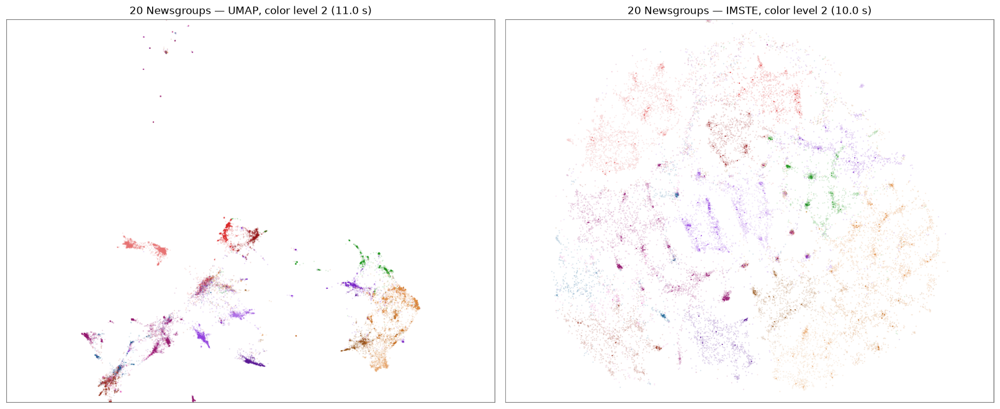

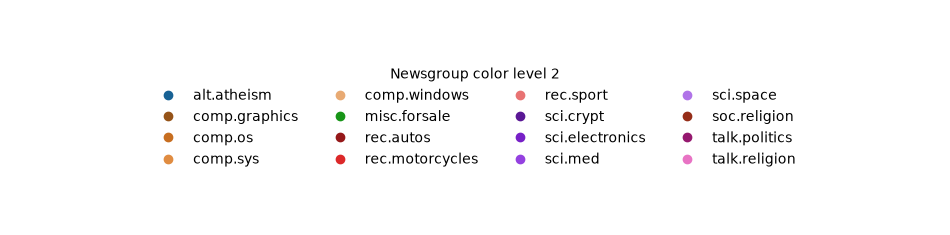

In [5]:
COLOR_LEVEL = 2  # Choose 1 (broad), 2 (middle), or 3 (specific) newsgroup groups.
fig = plot_20newsgroups_layouts(
    Z_umap, Z_imste, labels, category_names, texts, indices, timings,
    color_level=COLOR_LEVEL,
)
fig.show()